In [1]:

%pip install -q gwpy
%load_ext autoreload
%autoreload 2

import numpy as np

import sys, os
sys.path.insert(0, os.path.abspath('../..'))

import kalman.runtime.chrono as chrono
chrono.restart()
print('kalman imported')


Note: you may need to restart the kernel to use updated packages.
kalman imported


# Gravitational-Wave Polarization — Extended Kalman Filter (Jones Formalism)

> This notebook implements the polarization model from Amblard and Michel.
> For detector context — suspension violin modes, KAGRA, and strain sensitivity — see `04_MechanicalSuspension.ipynb`.

A gravitational wave (GW) at one detector produces a two-component signal. This signal has the Jones form:
$$
\mathbf{z}_t = a_t\,e^{i\psi_t}\begin{pmatrix}\cos(\theta_t/2) \\ \sin(\theta_t/2)\,e^{i\varphi_t}\end{pmatrix} + \boldsymbol{\nu}_t
$$

The terms are:
- $a_t > 0$ — the signal amplitude.
- $\psi_t$ — the carrier phase.
- $(\theta_t,\varphi_t)$ — the polarization angles on the Poincaré sphere.
- $\boldsymbol{\nu}_t\sim\mathcal{N}(0,\sigma_n^2 I_4)$ — the observation noise.

We estimate these quantities with an Extended Kalman Filter (EKF). The EKF state has 8 components:
$$
\mathbf{x}_t = [\underbrace{\log a_t,\;\dot{a}_t/a_t}_{\text{amplitude}},
                \underbrace{u_\psi,\;v_\psi}_{\text{phase}},
                \underbrace{u_\theta,\;v_\theta}_{\theta},
                \underbrace{u_\varphi,\;v_\varphi}_{\varphi}]^\top \in \mathbb{R}^8
$$

We track the log-amplitude, not the amplitude itself. This choice keeps $a_t = e^{x_0}$ positive.
It also removes a sign ambiguity: $(a,\psi)$ and $(-a,\psi+\pi)$ would otherwise describe the same
signal.

Each parameter pair follows a Langevin model. This model assumes constant velocity plus random
drift:
$$F = \begin{pmatrix}1 & \Delta t \\ 0 & 1\end{pmatrix}, \qquad
Q_{\text{block}} = \sigma_p^2\begin{pmatrix}\delta^3/3 & \delta^2/2 \\ \delta^2/2 & \delta\end{pmatrix}$$

Here $\delta$ is a bandwidth tuning parameter. It is independent of the sample step $\Delta t = 1/f_s$.


## The Model and Key Terms

The filter tracks a gravitational wave's polarization online. It uses an Extended Kalman Filter
(EKF).

The dynamics are linear: each parameter drifts smoothly over time. The measurement is nonlinear,
because it uses the Jones map described above. The filter linearizes this map at each step. This
linearized map is $H=\partial h/\partial x$.

**Key terms**
- **Jones vector** — the two-component complex signal that describes the two polarization channels.
- **Log-amplitude** $\ln a$ — the filter tracks $\ln a$, not $a$. This keeps the amplitude positive. It also removes the $(a,\psi)\to(-a,\psi+\pi)$ sign ambiguity.
- **Constant-velocity model** — each parameter $q$ follows $\dot q=\dot q,\ \ddot q=w$. This means smooth drift plus white acceleration noise.
- **Bandwidth knob** $\delta$ — sets the process-noise level. A larger $\delta$ gives faster tracking but more noise. It works independently of the sample step $\Delta t$.

The state vector has 8 components, one velocity term per parameter:
$$x=[\ln a,\,v_a,\,\psi,\,v_\psi,\,\theta,\,v_\theta,\,\phi,\,v_\phi]^\top,\qquad v_q=\dot q.$$

Each parameter pair $(q,\dot q)$ follows the same transition and noise model:
$$\dot q=\dot q,\quad \ddot q=w
\;\Rightarrow\;
F=\mathrm{blkdiag}\!\begin{bmatrix}1&\Delta t\\0&1\end{bmatrix}_{\!\times4},\qquad
Q_{\text{pair}}=\sigma^2\begin{bmatrix}\delta^3/3&\delta^2/2\\\delta^2/2&\delta\end{bmatrix}.$$

The measurement vector is $z=[\mathrm{Re}\,z_1,\mathrm{Im}\,z_1,\mathrm{Re}\,z_2,\mathrm{Im}\,z_2]^\top$, where:
$$z_1=a\,e^{i\psi}\cos(\theta/2),\qquad z_2=a\,e^{i\psi}\sin(\theta/2)\,e^{i\phi},\qquad a=e^{\ln a}.$$
The measurement noise covariance is $R=\sigma_n^2 I_4$.


In [2]:
from kalman.apps.gravitational.gravwave import (
    PolarizationModel,
    PolarizationState,
    PolarizationObservable,
    jones_signal,
)

print(f"PolarizationModel v{PolarizationModel.VERSION} imported from kalman.apps.gravitational.gravwave")
print(f"  {PolarizationModel.DESCRIPTION}")


PolarizationModel v6.1 imported from kalman.apps.gravitational.gravwave
  EKF for real-time estimation of gravitational-wave polarization parameters using the Jones formalism (Amblard & Michel).  8-D log-amplitude state, 4-D real observation.


## Step 1 — Build a Synthetic Signal

We first build a synthetic signal with known ground truth. This lets us measure the estimation
error exactly. The signal reproduces Section 4.1 of Amblard and Michel.

**Key terms**
- **Chirp** — a signal whose instantaneous frequency increases with time. Here the phase $\psi_t$ accelerates, like the inspiral of two orbiting compact objects.
- **Instantaneous frequency** — $\dot\psi/2\pi$, the time-derivative of the phase. It is the main diagnostic quantity of a chirp.
- **Polarization angles** $\theta_t,\varphi_t$ — slowly-varying parameters. They describe how the wave's two polarization channels mix.
- **SNR (signal-to-noise ratio)** — here $\sigma_n=0.3$ gives SNR ≈ 1.7. This is a genuinely noisy case.

The signal uses these true parameter functions:
$$a_t = 1 + 0.1\cos(2\pi\cdot 0.2\,t),\qquad \psi_t = 2\pi t\,\bigl(1 + 0.98\,t^4/T^4\bigr)$$
$$\theta_t = \tfrac{\pi}{2}\bigl(1 + \tfrac12\sin(2\pi\cdot 0.05\,t)\bigr),\qquad
\varphi_t = \pi\bigl(1 + \tfrac12\sin(2\pi\cdot 0.1\,t + \xi)\bigr)$$

We sample this signal at 100 Hz over $[0,T]$, with a random phase $\xi$. The constant-velocity
model can follow this chirp. This works because the frequency $v^\psi\approx\dot\psi$ stays nearly
constant over the short model timescale $\delta$.


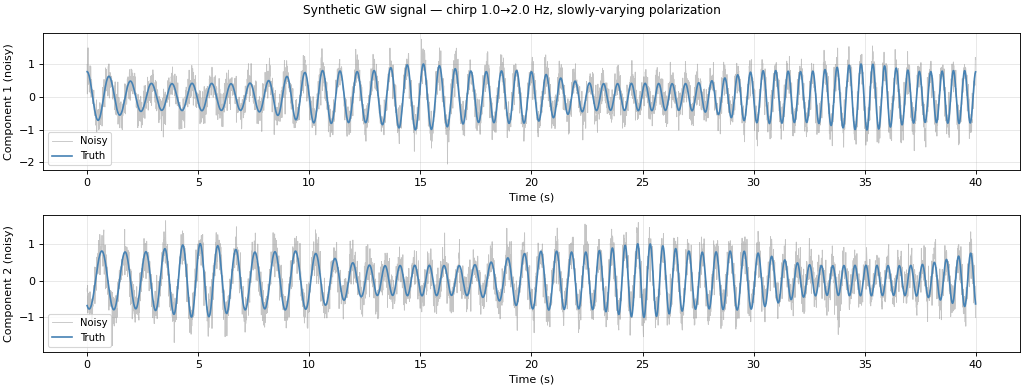

N=4000 | σ_n=0.3 | SNR ≈ 1.67
Chirp: 1.0→2.0 Hz | max d²ψ/dt² = 0.1571 rad/s²


In [3]:
fs  = 100.0     # sample rate [Hz]
T   = 40.0      # duration [s]
t   = np.arange(int(T * fs)) / fs

np.random.seed(0)
xi = np.random.uniform(0, 2 * np.pi)

# Amplitude: slow cosine oscillation
a_true     = 1.0 + 0.1 * np.cos(2 * np.pi * 0.2 * t)

# Carrier: chirp from 1 Hz to 2 Hz over T seconds
f0_chirp = 1.0
fT_chirp = 2.0
chirp_rate = (fT_chirp - f0_chirp) / T   # 0.025 Hz/s
psi_true   = 2 * np.pi * (f0_chirp * t + 0.5 * chirp_rate * t**2)

# Polarization: slowly-varying
theta_true = (np.pi / 2) * (1.0 + 0.5 * np.sin(2 * np.pi * 0.05 * t))
phi_true   = np.pi       * (1.0 + 0.5 * np.sin(2 * np.pi * 0.10 * t + xi))

# Build clean bivariate Jones signal
N = len(t)
z_clean = np.zeros((N, 2), dtype=complex)
for k in range(N):
    z_clean[k] = jones_signal(a_true[k], psi_true[k], theta_true[k], phi_true[k])

# Observation noise  (σ_n = 0.3 → SNR ≈ 1.7)
sigma_n = 0.3
noise = (np.random.normal(0, sigma_n, (N, 2))
       + 1j * np.random.normal(0, sigma_n, (N, 2)))
z_noisy = z_clean + noise

# Real 4-column measurement array
zk = np.column_stack([z_noisy[:, 0].real, z_noisy[:, 0].imag,
                      z_noisy[:, 1].real, z_noisy[:, 1].imag])

import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05
fig, axes = plt.subplots(2, 1, figsize=(13, 5))
for i, label in enumerate(['Component 1 (noisy)', 'Component 2 (noisy)']):
    axes[i].plot(t, z_noisy[:, i].real,  alpha=0.45, color='gray', lw=0.8, label='Noisy')
    axes[i].plot(t, z_clean[:, i].real,  color='steelblue',        lw=1.5, label='Truth')
    axes[i].set_xlabel('Time (s)')
    axes[i].set_ylabel(label)
    axes[i].legend(fontsize=9)
    axes[i].grid(True, alpha=0.3)

freq_true_plot = np.gradient(psi_true, 1/fs) / (2 * np.pi)
fig.suptitle(f'Synthetic GW signal — chirp {f0_chirp}→{fT_chirp} Hz, slowly-varying polarization', fontsize=11)
plt.tight_layout()
plt.show()

alpha_chirp = 2 * np.pi * chirp_rate   # d²ψ/dt² in rad/s²
print(f"N={N} | σ_n={sigma_n} | SNR ≈ {np.std(z_clean[:, 0].real)/sigma_n:.2f}")
print(f"Chirp: {f0_chirp}→{fT_chirp} Hz | max d²ψ/dt² = {alpha_chirp:.4f} rad/s²")

## Step 2 — Run the EKF on the Synthetic Signal

We run `PolarizationModel`, our EKF, on the synthetic signal. We tune its noise parameters below.

**How to read the parameters.** Each $\sigma$ sets how fast the filter lets a quantity drift. This
is the process noise. A larger $\sigma$ gives faster tracking but a noisier estimate. $\sigma_n$ is
the measurement noise, not a process noise. The bandwidth knob $\delta$ trades tracking speed
against variance reduction.

| Parameter | Value | Meaning |
|---|---|---|
| `delta` | 0.5 s | bandwidth tuning |
| `sigma_n` | 0.3 | observation noise std |
| `sigma_a` | 0.05 | amplitude process noise |
| `sigma_psi` | 0.6 | phase / frequency process noise |
| `sigma_theta` | 0.05 | θ-polarization process noise |
| `sigma_phi` | 0.05 | φ-polarization process noise |

**Key term — the PLL bandwidth condition.** Tracking a chirp works like a phase-locked loop (PLL).
The loop bandwidth is $\omega_n=\sqrt{\sigma_\psi^2\,\delta/\sigma_n^2}$. This bandwidth must stay
high enough that the chirp's acceleration does not cause the filter to lose lock. The lag
condition is $\varepsilon_\varphi=\ddot\psi/\omega_n^2 < 0.1$ rad.

With $\delta=0.5$ and $\sigma_\psi=0.6$, we get $\omega_n=1.41$ rad/s and
$\varepsilon_\varphi\approx0.079$ rad. This value is below 0.1 rad, so the filter keeps lock.


/Users/marcomeyer/Software/kalman/kalman-framework/share/notebooks/kalman/framework/engine.py:122: RuntimeWarning: divide by zero encountered in matmul
  return xk, F @ P @ F.T + Q, F
/Users/marcomeyer/Software/kalman/kalman-framework/share/notebooks/kalman/framework/engine.py:122: RuntimeWarning: overflow encountered in matmul
  return xk, F @ P @ F.T + Q, F
/Users/marcomeyer/Software/kalman/kalman-framework/share/notebooks/kalman/framework/engine.py:122: RuntimeWarning: invalid value encountered in matmul
  return xk, F @ P @ F.T + Q, F


Chrono summary:
    #   label                       t          ΔT
  ───   ─────────────────   ─────────   ─────────
    1.  Model initialized      0.2 ms      0.2 ms
    2.  EKF completed        780.5 ms    780.3 ms
  ───   ─────────────────   ─────────   ─────────
        total                780.5 ms


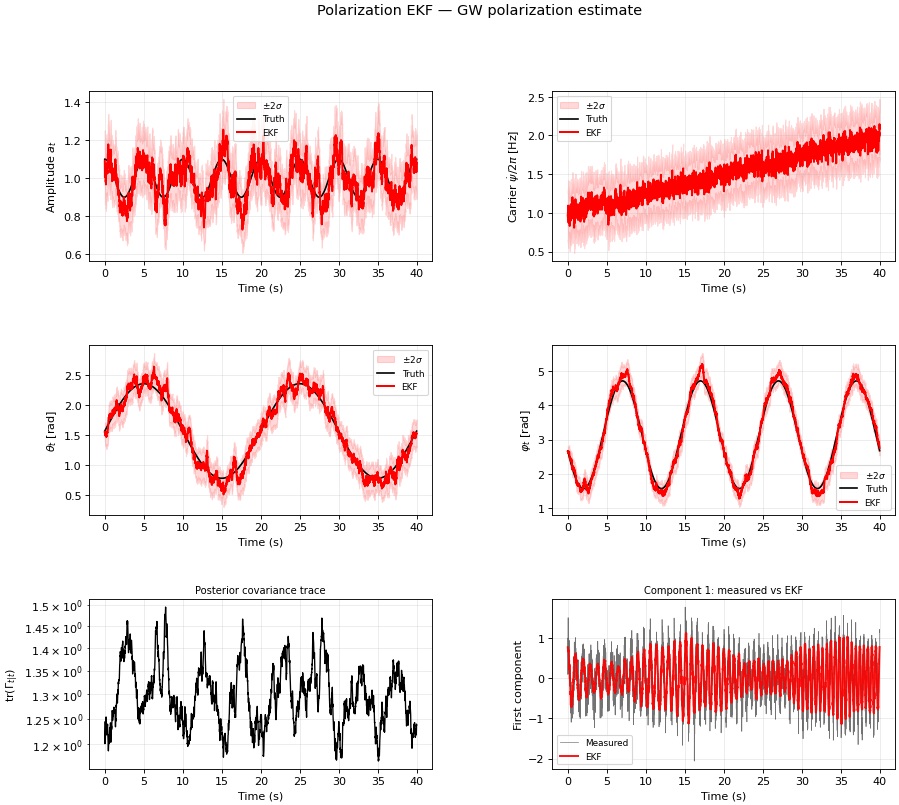

In [4]:
from scipy.linalg import solve_discrete_are

dt = 1.0 / fs
delta = 0.5
sigma_psi_val, sigma_a_val, sigma_theta_val, sigma_phi_val = 0.6, 0.05, 0.05, 0.05

def dare_block(sigma, delta):
    # Steady-state covariance for one (q, q_dot) pair, via the discrete algebraic Riccati equation.
    A_block = np.array([[1.0, dt], [0.0, 1.0]])
    Q_block = sigma**2 * np.array([[delta**3 / 3, delta**2 / 2], [delta**2 / 2, delta]])
    H_block = np.array([[1.0, 0.0]])
    R_block = np.array([[sigma_n**2]])
    try:
        return solve_discrete_are(A_block.T, H_block.T, Q_block, R_block)
    except:
        return np.diag([1e-4, sigma**2 * delta])

P0 = np.zeros((8, 8))
P0[0:2, 0:2] = dare_block(sigma_a_val,     delta)
P0[2:4, 2:4] = dare_block(sigma_psi_val,   delta)
P0[4:6, 4:6] = dare_block(sigma_theta_val, delta)
P0[6:8, 6:8] = dare_block(sigma_phi_val,   delta)

chrono.restart()
model = PolarizationModel(
    "GW_synth", fs=fs, delta=delta,
    sigma_a=sigma_a_val, sigma_psi=sigma_psi_val,
    sigma_theta=sigma_theta_val, sigma_phi=sigma_phi_val,
    sigma_n=sigma_n, P0=P0)

v_psi_init = 2 * np.pi * f0_chirp
model.initial_state([np.log(a_true[0]), 0.0,
                     psi_true[0] - dt * v_psi_init, v_psi_init,
                     theta_true[0], 0.0,
                     phi_true[0],   0.0])
chrono.lap("Model initialized")
record = model.filter(zk, smooth=False)
chrono.lap("EKF completed")
chrono.summary()

# Derived quantities (reused by later sections)
xk, Pk    = record.xk, record.Pk
p_hat     = model.physical_parameters(record)
a_hat, psi_hat   = p_hat["amplitude"], p_hat["psi"]
theta_hat, phi_hat, freq_hat = p_hat["theta"], p_hat["phi"], p_hat["freq"]
freq_true = np.gradient(psi_true, 1 / fs) / (2 * np.pi)

# Signature figure: amplitude / carrier freq / theta / phi (+/-2sig) + covariance + comp-1.
_ = model.plot(record,
           truth=dict(amplitude=a_true, freq=freq_true, theta=theta_true, phi=phi_true),
           measured=z_noisy[:, 0])

### Dynamic Replay — Measured vs EKF (Time Slider)

Slide the window across the signal. Watch the EKF reconstruction track the noisy measurements of
the first Jones component. The plot shows both signals with a legend, so the comparison is clear.


In [5]:
# Dynamic replay -- slide a window across the signal: measured first component vs EKF.
model.plot(record, interactive=True, measured=z_noisy[:, 0])

## Step 3 — Check the Covariance Trace and Spectrogram

Two diagnostics show whether the filter tracks the signal correctly, not just whether it produces
numbers.

**Key terms**
- **Covariance trace** $\mathrm{tr}(\Gamma_{t|t})$ — the sum of the state variances. This single number summarizes the filter's total posterior uncertainty. Spikes flag trouble, such as low SNR, lost lock, or a chirp too fast for the chosen bandwidth.
- **Spectrogram ridge** — in a time-frequency plot, the chirp forms a 1-D curve. Noise spreads across the whole plane instead. We overlay the EKF's instantaneous-frequency estimate $\hat f(t)=v^\psi/2\pi$ on this ridge. This overlay is the most reliable visual check of tracking.

What to look for: the estimated frequency should follow the spectrogram ridge closely. The
covariance trace should stay low, except during the fastest part of the chirp.


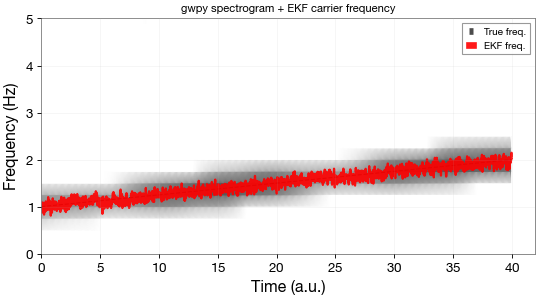

In [6]:
import matplotlib.pyplot as plt
from gwpy.timeseries import TimeSeries

def to_poincare(theta, phi):
    x = np.sin(theta) * np.cos(phi)   # S2
    y = np.sin(theta) * np.sin(phi)   # S3
    z = np.cos(theta)                  # S1
    return x, y, z

x_true, y_true, z_true = to_poincare(theta_true, phi_true)
x_hat,  y_hat,  z_hat  = to_poincare(theta_hat,  phi_hat)

ts_synth   = TimeSeries(z_noisy[:, 0].real, sample_rate=fs, t0=0)
spec_synth = ts_synth.spectrogram2(fftlength=4.0, overlap=3.9)
t_spec = spec_synth.times.value
f_spec = spec_synth.frequencies.value
Sxx    = spec_synth.value.T

fig, ax_sp = plt.subplots(figsize=(7, 4))
ax_sp.pcolormesh(t_spec, f_spec, 10 * np.log10(Sxx + 1e-30),
                 shading='gouraud', cmap='gray_r', vmin=-20, vmax=10)
ax_sp.plot(t, freq_true, color='black', lw=1.0, ls='--', alpha=0.7, label='True freq.')
ax_sp.plot(t, freq_hat,  color='red',   lw=2.0,           alpha=0.9, label='EKF freq.')
ax_sp.set_xlabel('Time (a.u.)')
ax_sp.set_ylabel('Frequency (Hz)')
ax_sp.set_ylim(0, 5)
ax_sp.set_title('gwpy spectrogram + EKF carrier frequency', fontsize=10)
ax_sp.legend(fontsize=9)
ax_sp.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

### Interactive Poincaré Sphere — Synthetic Signal

The horizontal slider sets the time. The trajectory builds up as time increases. The vertical bar
on the right rotates the globe in azimuth.


In [7]:
# Interactive Poincaré sphere — time slider + vertical rotation bar
model.plot_poincare(record,
                    interactive=True,
                    truth_theta=theta_true,
                    truth_phi=phi_true)

## Step 4 — Test on a Numerical GW Signal (Precessing Binary)

This is a harder test. We build a gravitational-wave-like signal from two precessing, coalescing
black holes. In this signal, the polarization angles themselves evolve over time.

**Key terms**
- **Precession** — the binary's orbital plane slowly rotates. So $\theta_t,\varphi_t$ drift on the precession timescale, while $\psi_t$ sweeps upward as a chirp during the inspiral.
- **Bias-variance trade-off** — for a fast chirp, the hard part is tracking $v^\psi$. A larger $\delta$ (here 0.9) and $\sigma_\psi$ (2.0) widen the effective bandwidth. This smooths the frequency estimate but adds some lag.

This test mirrors Section 4.2 of Amblard and Michel. It uses a parametric chirp model, since a
full numerical-relativity waveform would need extra dependencies. We test it against Gaussian
white noise with $\sigma_n=0.3$.


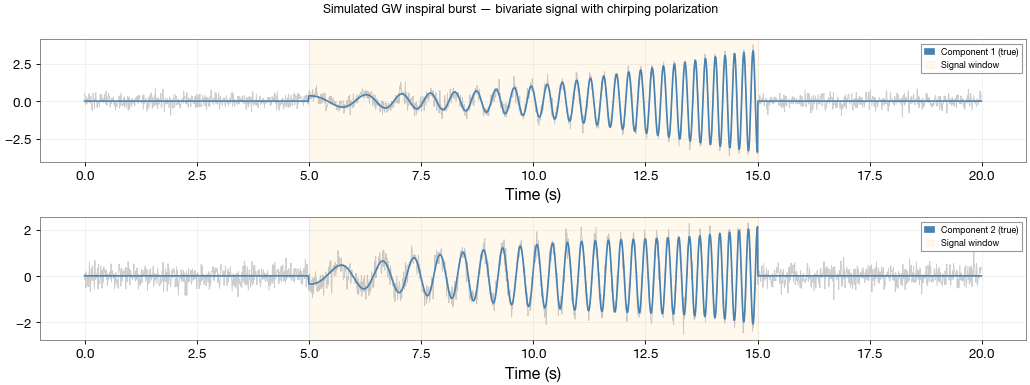

In [8]:
# ─── Synthetic GW-like chirp with precessing polarization ────────
fs_gw = 100.0
T_gw  = 20.0
t_gw  = np.arange(int(T_gw * fs_gw)) / fs_gw
N_gw  = len(t_gw)

t_start, t_end = 5.0, 15.0
window = (t_gw >= t_start) & (t_gw <= t_end)
t_sig = t_gw[window] - t_start
T_sig = t_end - t_start

f_start, f_end = 0.5, 5.0
chirp_rate = (f_end - f_start) / T_sig
psi_sig = 2 * np.pi * (f_start * t_sig + 0.5 * chirp_rate * t_sig**2)

a_sig = 0.5 * (1 + t_sig / T_sig) ** 3

theta_sig = (np.pi / 2) * (1 + 0.3 * np.sin(2 * np.pi * 0.08 * t_sig))
phi_sig   = np.pi       * (1 + 0.3 * np.sin(2 * np.pi * 0.05 * t_sig))

a_gw = np.zeros(N_gw)
a_gw[window] = a_sig
psi_gw = np.zeros(N_gw)
psi_gw[window] = psi_sig
theta_gw = np.full(N_gw, np.pi / 2)
theta_gw[window] = theta_sig
phi_gw = np.full(N_gw, np.pi)
phi_gw[window] = phi_sig

z_gw_clean = np.zeros((N_gw, 2), dtype=complex)
for k in range(N_gw):
    z_gw_clean[k] = jones_signal(a_gw[k], psi_gw[k], theta_gw[k], phi_gw[k])

sigma_n_gw = 0.3
np.random.seed(7)
noise_gw = (np.random.normal(0, sigma_n_gw, (N_gw, 2))
           + 1j * np.random.normal(0, sigma_n_gw, (N_gw, 2)))
z_gw_noisy = z_gw_clean + noise_gw

zk_gw = np.column_stack([z_gw_noisy[:, 0].real, z_gw_noisy[:, 0].imag,
                          z_gw_noisy[:, 1].real, z_gw_noisy[:, 1].imag])

fig, axes = plt.subplots(2, 1, figsize=(13, 5))
for i in range(2):
    axes[i].plot(t_gw, z_gw_noisy[:, i].real, color='gray',      alpha=0.4, lw=0.8)
    axes[i].plot(t_gw, z_gw_clean[:, i].real, color='steelblue', lw=1.5, label=f'Component {i+1} (true)')
    axes[i].axvspan(t_start, t_end, alpha=0.07, color='orange', label='Signal window')
    axes[i].set_xlabel('Time (s)')
    axes[i].legend(fontsize=8)
    axes[i].grid(True, alpha=0.3)
fig.suptitle('Simulated GW inspiral burst — bivariate signal with chirping polarization', fontsize=11)
plt.tight_layout()
plt.show()

Inspiral chirp: 0.5→5.0 Hz in 10.0 s | d²ψ/dt²=2.827 rad/s²
ωn=6.32 rad/s | ε_φ=0.0707 rad
Chrono summary:
    #   label                       t          ΔT
  ───   ─────────────────   ─────────   ─────────
    1.  Model initialized      0.3 ms      0.3 ms
    2.  EKF completed        139.9 ms    139.6 ms
  ───   ─────────────────   ─────────   ─────────
        total                139.9 ms


/Users/marcomeyer/Software/kalman/kalman-framework/share/notebooks/kalman/framework/engine.py:122: RuntimeWarning: divide by zero encountered in matmul
  return xk, F @ P @ F.T + Q, F
/Users/marcomeyer/Software/kalman/kalman-framework/share/notebooks/kalman/framework/engine.py:122: RuntimeWarning: overflow encountered in matmul
  return xk, F @ P @ F.T + Q, F
/Users/marcomeyer/Software/kalman/kalman-framework/share/notebooks/kalman/framework/engine.py:122: RuntimeWarning: invalid value encountered in matmul
  return xk, F @ P @ F.T + Q, F


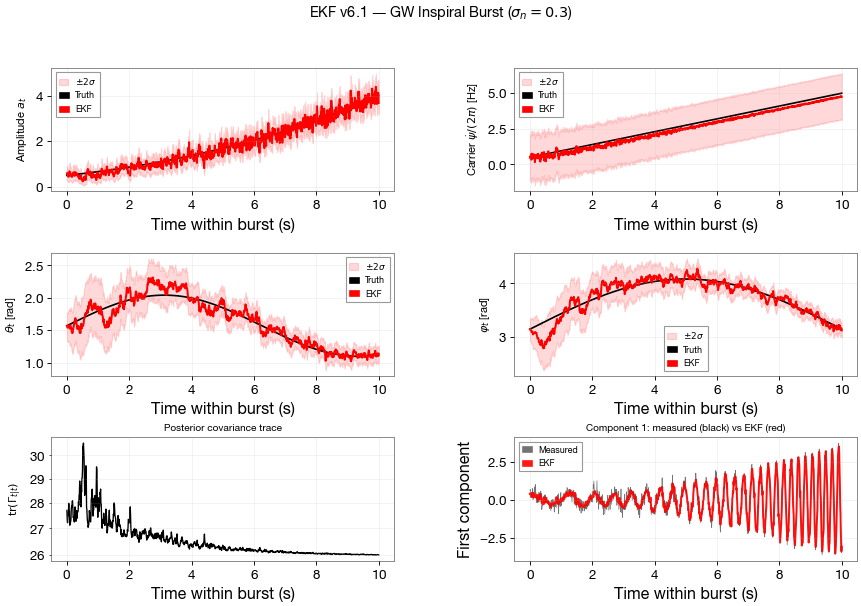

In [9]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.mplot3d import Axes3D   # noqa: F401
from gwpy.timeseries import TimeSeries
from scipy.linalg import solve_discrete_are

zk_burst = zk_gw[window]
N_burst  = zk_burst.shape[0]

dt_gw      = 1.0 / fs_gw
delta_gw   = 0.9
sigma_psi_gw   = 2.0
sigma_a_gw     = 0.3
sigma_theta_gw = 0.05
sigma_phi_gw   = 0.05

def dare_block_gw(sigma, delta):
    # Steady-state covariance for one (q, q_dot) pair, via the discrete algebraic Riccati equation.
    A_block = np.array([[1.0, dt_gw], [0.0, 1.0]])
    Q_block = sigma**2 * np.array([[delta**3 / 3, delta**2 / 2], [delta**2 / 2, delta]])
    H_block = np.array([[1.0, 0.0]])
    R_block = np.array([[sigma_n_gw**2]])
    try:
        return solve_discrete_are(A_block.T, H_block.T, Q_block, R_block)
    except:
        return np.diag([1e-4, sigma**2 * delta])

P0_gw = np.zeros((8, 8))
P0_gw[0:2, 0:2] = dare_block_gw(sigma_a_gw,     delta_gw)
P0_gw[2:4, 2:4] = dare_block_gw(sigma_psi_gw,   delta_gw)
P0_gw[4:6, 4:6] = dare_block_gw(sigma_theta_gw, delta_gw)
P0_gw[6:8, 6:8] = dare_block_gw(sigma_phi_gw,   delta_gw)

omega_n_gw = np.sqrt(sigma_psi_gw**2 * delta_gw / sigma_n_gw**2)
alpha_gw   = 2 * np.pi * (f_end - f_start) / T_sig
print(f"Inspiral chirp: {f_start}→{f_end} Hz in {T_sig} s | d²ψ/dt²={alpha_gw:.3f} rad/s²")
print(f"ωn={omega_n_gw:.2f} rad/s | ε_φ={alpha_gw/omega_n_gw**2:.4f} rad")

chrono.restart()
model_gw = PolarizationModel(
    'GW_inspiral',
    fs=fs_gw, delta=delta_gw,
    sigma_a=sigma_a_gw, sigma_psi=sigma_psi_gw,
    sigma_theta=sigma_theta_gw, sigma_phi=sigma_phi_gw,
    sigma_n=sigma_n_gw,
    P0=P0_gw,
)

v_psi_gw_init = 2 * np.pi * f_start
model_gw.initial_state([np.log(a_sig[0]),           0.0,
                         -dt_gw * v_psi_gw_init,    v_psi_gw_init,
                         theta_sig[0],               0.0,
                         phi_sig[0],                 0.0])

chrono.lap("Model initialized")
record_gw = model_gw.filter(zk_burst, smooth=False)
chrono.lap("EKF completed")
chrono.summary()

xk_gw   = record_gw.xk
Pk_gw   = record_gw.Pk
sig2_gw = 2.0 * np.sqrt(np.diagonal(Pk_gw, axis1=1, axis2=2))

a_hat_gw     = np.exp(xk_gw[:, 0])
psi_hat_gw   = xk_gw[:, 2]
theta_hat_gw = xk_gw[:, 4]
phi_hat_gw   = xk_gw[:, 6]
freq_hat_gw  = xk_gw[:, 3] / (2 * np.pi)
freq_true_burst = f_start + chirp_rate * t_sig

sig2_a_gw  = a_hat_gw * sig2_gw[:, 0]
trace_P_gw = np.trace(Pk_gw, axis1=1, axis2=2)
z1_hat_gw  = a_hat_gw * np.exp(1j * psi_hat_gw) * np.cos(theta_hat_gw / 2)

fig1 = plt.figure(figsize=(13, 8))
gs   = gridspec.GridSpec(3, 2, figure=fig1, hspace=0.50, wspace=0.35)

params_gw = [
    (a_hat_gw,     a_sig,           sig2_a_gw,               r'Amplitude $a_t$'),
    (freq_hat_gw,  freq_true_burst, sig2_gw[:, 3]/(2*np.pi), r'Carrier $\dot{\psi}/(2\pi)$ [Hz]'),
    (theta_hat_gw, theta_sig,       sig2_gw[:, 4],           r'$\theta_t$ [rad]'),
    (phi_hat_gw,   phi_sig,         sig2_gw[:, 6],           r'$\varphi_t$ [rad]'),
]

for idx, (hat, true, s2, ylabel) in enumerate(params_gw):
    ax = fig1.add_subplot(gs[idx // 2, idx % 2])
    ax.fill_between(t_sig, hat - s2, hat + s2, alpha=0.15, color='red', label=r'$\pm 2\sigma$')
    ax.plot(t_sig, true, color='black', lw=1.5, label='Truth')
    ax.plot(t_sig, hat,  color='red',   lw=1.8, label='EKF')
    ax.set_xlabel('Time within burst (s)')
    ax.set_ylabel(ylabel, fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.25)

ax_cov = fig1.add_subplot(gs[2, 0])
ax_cov.semilogy(t_sig, trace_P_gw, color='black', lw=1.2)
ax_cov.set_xlabel('Time within burst (s)')
ax_cov.set_ylabel(r'$\mathrm{tr}(\Gamma_{t|t})$', fontsize=10)
ax_cov.set_title('Posterior covariance trace', fontsize=9)
ax_cov.grid(True, alpha=0.25, which='both')

ax_sig = fig1.add_subplot(gs[2, 1])
ax_sig.plot(t_sig, zk_burst[:, 0], color='black', lw=0.6, alpha=0.55, label='Measured')
ax_sig.plot(t_sig, z1_hat_gw.real, color='red',   lw=1.8, alpha=0.90, label='EKF')
ax_sig.set_xlabel('Time within burst (s)')
ax_sig.set_ylabel('First component')
ax_sig.set_title('Component 1: measured (black) vs EKF (red)', fontsize=9)
ax_sig.legend(fontsize=8)
ax_sig.grid(True, alpha=0.25)

fig1.suptitle(r'EKF v6.1 — GW Inspiral Burst ($\sigma_n = 0.3$)', fontsize=13)
plt.show()

### Interactive Poincaré Sphere — GW Inspiral Burst

This plot uses the same controls: a time slider and a vertical rotation bar.


In [10]:
# Interactive Poincaré sphere for the precessing inspiral burst
model_gw.plot_poincare(record_gw,
                        interactive=True,
                        truth_theta=theta_sig,
                        truth_phi=phi_sig)

## Step 5 — Test the Effect of Real Interferometer Noise (Colored Noise)

Real GW detector noise, from LIGO or Virgo, is not white. It has a colored power spectral density
(PSD), with many narrow-band spectral lines. These lines come from sources like suspension violin
modes and power-line harmonics.

The paper's pipeline applies three filters, in order:
1. A high-pass filter, to remove very-low-frequency seismic noise.
2. Two notch filters (band-reject), at known line frequencies (normalized 0.012 and 0.076).
3. A low-pass filter, at normalized frequency 0.2. GW signals sit at low frequencies relative to the sample rate.

### Key Finding (Section 4.3)

> The EKF can still track the carrier frequency correctly after notch filtering. This works
> because the Langevin state model provides smoothness across the frequency gaps.

We reproduce this result. We add a synthetic colored noise floor to the same signal, then apply
the same pre-filters.

### Why Colored Noise Degrades Polarization but Not Frequency

- **Frequency** is tracked through the phase velocity $v^\psi$. The chirp lives on a thin ridge in the time-frequency plane, well separated from broadband colored noise.
- **Polarization** parameters $(\theta, \varphi)$ control the amplitude ratio and phase difference between the two components. At low SNR, these parameters are buried in the noise floor. They cannot be separated from the noise's spectral shape.

This is the fundamental observability limit discussed in Section 5 of the paper.


Chrono summary:
    #   label                                   t          ΔT
  ───   ─────────────────────────────   ─────────   ─────────
    1.  EKF (colored noise) completed    127.5 ms    127.5 ms
  ───   ─────────────────────────────   ─────────   ─────────
        total                            127.5 ms


/Users/marcomeyer/Software/kalman/kalman-framework/share/notebooks/kalman/framework/engine.py:122: RuntimeWarning: divide by zero encountered in matmul
  return xk, F @ P @ F.T + Q, F
/Users/marcomeyer/Software/kalman/kalman-framework/share/notebooks/kalman/framework/engine.py:122: RuntimeWarning: overflow encountered in matmul
  return xk, F @ P @ F.T + Q, F
/Users/marcomeyer/Software/kalman/kalman-framework/share/notebooks/kalman/framework/engine.py:122: RuntimeWarning: invalid value encountered in matmul
  return xk, F @ P @ F.T + Q, F


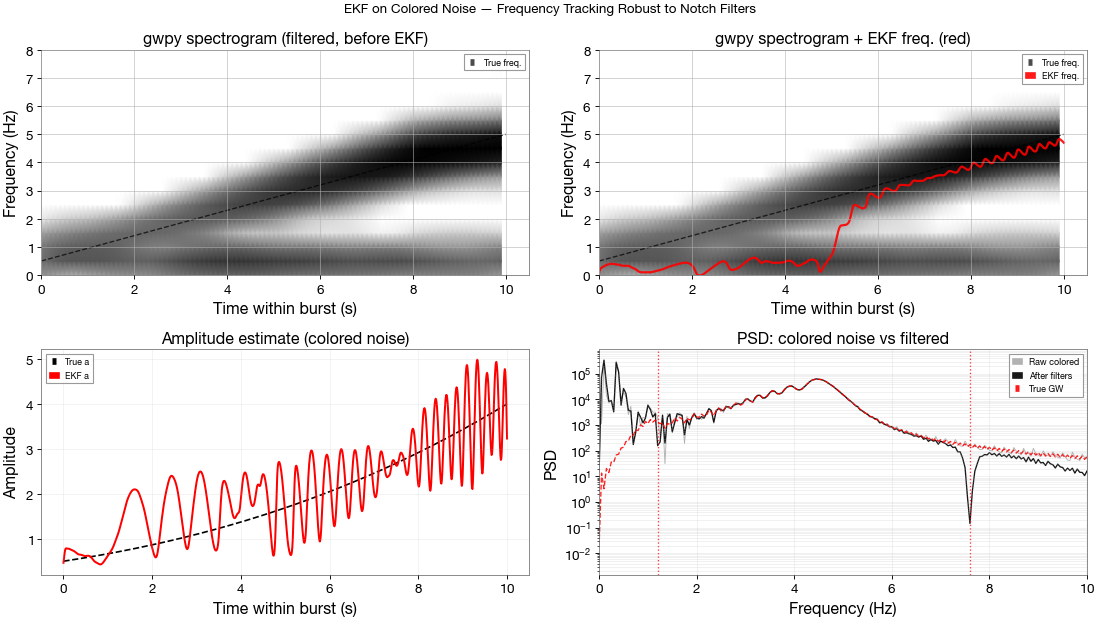

In [11]:
from scipy.signal import butter, sosfilt, iirnotch, sosfiltfilt, tf2sos
from scipy.linalg import solve_discrete_are
from gwpy.timeseries import TimeSeries

np.random.seed(99)

white = np.random.normal(0, 1.0, (N_gw, 2)) + 1j * np.random.normal(0, 1.0, (N_gw, 2))

def colour_noise(w, fs, order=2, fc=0.3):
    sos = butter(order, fc, btype='low', fs=fs, output='sos')
    return sosfilt(sos, w, axis=0)

colored = colour_noise(white, fs_gw)
colored = colored / np.std(colored) * sigma_n_gw * 3

z_gw_colored = z_gw_clean + colored

def apply_filters(sig_2d, fs):
    out = np.zeros_like(sig_2d)
    for col in range(sig_2d.shape[1]):
        s = sig_2d[:, col]
        sos_hp = butter(2, 0.02, btype='high', fs=fs, output='sos')
        s = sosfiltfilt(sos_hp, s)
        for fn in [0.012 * fs, 0.076 * fs]:
            b, a_c = iirnotch(fn, Q=30, fs=fs)
            sos_n = tf2sos(b, a_c)
            s = sosfiltfilt(sos_n, s)
        sos_lp = butter(4, 0.2 * fs / 2, btype='low', fs=fs, output='sos')
        s = sosfiltfilt(sos_lp, s)
        out[:, col] = s
    return out

z_real     = np.column_stack([z_gw_colored[:, 0].real, z_gw_colored[:, 1].real])
z_filtered = apply_filters(z_real, fs_gw)

from scipy.signal import hilbert as _hilbert
z_analytic = np.zeros((N_gw, 2), dtype=complex)
for col in range(2):
    z_analytic[:, col] = _hilbert(z_filtered[:, col])

zk_col_full  = np.column_stack([z_analytic[:, 0].real, z_analytic[:, 0].imag,
                                 z_analytic[:, 1].real, z_analytic[:, 1].imag])
zk_col_burst = zk_col_full[window]

dt_gw       = 1.0 / fs_gw
delta_col   = 0.9
sigma_psi_col   = 2.0
sigma_a_col     = 0.3
sigma_theta_col = 0.05
sigma_phi_col   = 0.05

def dare_block_col(sigma, delta):
    # Steady-state covariance for one (q, q_dot) pair, via the discrete algebraic Riccati equation.
    A_block = np.array([[1.0, dt_gw], [0.0, 1.0]])
    Q_block = sigma**2 * np.array([[delta**3 / 3, delta**2 / 2], [delta**2 / 2, delta]])
    H_block = np.array([[1.0, 0.0]])
    R_block = np.array([[sigma_n_gw**2]])
    try:
        return solve_discrete_are(A_block.T, H_block.T, Q_block, R_block)
    except:
        return np.diag([1e-4, sigma**2 * delta])

P0_col = np.zeros((8, 8))
P0_col[0:2, 0:2] = dare_block_col(sigma_a_col,     delta_col)
P0_col[2:4, 2:4] = dare_block_col(sigma_psi_col,   delta_col)
P0_col[4:6, 4:6] = dare_block_col(sigma_theta_col, delta_col)
P0_col[6:8, 6:8] = dare_block_col(sigma_phi_col,   delta_col)

chrono.restart()
model_col = PolarizationModel(
    'GW_colored',
    fs=fs_gw, delta=delta_col,
    sigma_a=sigma_a_col, sigma_psi=sigma_psi_col,
    sigma_theta=sigma_theta_col, sigma_phi=sigma_phi_col,
    sigma_n=sigma_n_gw,
    P0=P0_col,
)

v_psi_col_init = 2 * np.pi * f_start
model_col.initial_state([np.log(a_sig[0]),           0.0,
                          -dt_gw * v_psi_col_init,   v_psi_col_init,
                          theta_sig[0],               0.0,
                          phi_sig[0],                 0.0])

record_col = model_col.filter(zk_col_burst, smooth=False)
chrono.lap("EKF (colored noise) completed")
chrono.summary()

xk_col   = record_col.xk
freq_col = xk_col[:, 3] / (2 * np.pi)
a_col    = np.exp(xk_col[:, 0])

freq_true_burst = f_start + chirp_rate * t_sig

ts_filt    = TimeSeries(z_filtered[window, 0], sample_rate=fs_gw, t0=0)
spec_filt  = ts_filt.spectrogram2(fftlength=2.0, overlap=1.9)
t_filt_sp  = spec_filt.times.value
f_filt_sp  = spec_filt.frequencies.value
Sxx_filt   = spec_filt.value.T

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].pcolormesh(t_filt_sp, f_filt_sp, 10*np.log10(Sxx_filt + 1e-30),
                       shading='gouraud', cmap='gray_r', vmin=-30, vmax=5)
axes[0, 0].plot(t_sig, freq_true_burst, '--', color='black', lw=1.2, alpha=0.7, label='True freq.')
axes[0, 0].set_ylim(0, 8)
axes[0, 0].set_xlabel('Time within burst (s)')
axes[0, 0].set_ylabel('Frequency (Hz)')
axes[0, 0].set_title('gwpy spectrogram (filtered, before EKF)')
axes[0, 0].legend(fontsize=8)

axes[0, 1].pcolormesh(t_filt_sp, f_filt_sp, 10*np.log10(Sxx_filt + 1e-30),
                       shading='gouraud', cmap='gray_r', vmin=-30, vmax=5)
axes[0, 1].plot(t_sig, freq_true_burst, '--', color='black', lw=1.2, alpha=0.7, label='True freq.')
axes[0, 1].plot(t_sig, freq_col,             color='red',   lw=2.0, alpha=0.9, label='EKF freq.')
axes[0, 1].set_ylim(0, 8)
axes[0, 1].set_xlabel('Time within burst (s)')
axes[0, 1].set_ylabel('Frequency (Hz)')
axes[0, 1].set_title('gwpy spectrogram + EKF freq. (red)')
axes[0, 1].legend(fontsize=8)

axes[1, 0].plot(t_sig, a_sig,  color='black', lw=1.5, ls='--', label='True a')
axes[1, 0].plot(t_sig, a_col,  color='red',   lw=1.8, label='EKF a')
axes[1, 0].set_xlabel('Time within burst (s)')
axes[1, 0].set_ylabel('Amplitude')
axes[1, 0].set_title('Amplitude estimate (colored noise)')
axes[1, 0].legend(fontsize=8)
axes[1, 0].grid(True, alpha=0.25)

from numpy.fft import rfft, rfftfreq
freqs_psd = rfftfreq(N_gw, 1/fs_gw)
S_col_raw  = np.abs(rfft(z_real[:, 0]))**2
S_col_filt = np.abs(rfft(z_filtered[:, 0]))**2
S_clean_gw = np.abs(rfft(z_gw_clean[:, 0].real))**2
axes[1, 1].semilogy(freqs_psd, S_col_raw,  color='gray',   alpha=0.6, lw=0.8, label='Raw colored')
axes[1, 1].semilogy(freqs_psd, S_col_filt, color='black',  alpha=0.9, lw=1.2, label='After filters')
axes[1, 1].semilogy(freqs_psd, S_clean_gw, color='red',    alpha=0.9, lw=1.2, ls='--', label='True GW')
for fn in [0.012 * fs_gw, 0.076 * fs_gw]:
    axes[1, 1].axvline(fn, ls=':', color='red', lw=1.2, alpha=0.8)
axes[1, 1].axvline(0.2 * fs_gw / 2, ls='--', color='black', lw=1.0, alpha=0.6)
axes[1, 1].set_xlim(0, 10)
axes[1, 1].set_xlabel('Frequency (Hz)')
axes[1, 1].set_ylabel('PSD')
axes[1, 1].set_title('PSD: colored noise vs filtered')
axes[1, 1].legend(fontsize=8)
axes[1, 1].grid(True, alpha=0.3, which='both')

fig.suptitle('EKF on Colored Noise — Frequency Tracking Robust to Notch Filters', fontsize=12)
plt.tight_layout()
plt.show()

## Possible Improvements and Extensions

### 1. RTS Backward Smoother
A backward smoother would improve the posterior variance, at the cost of added latency. The paper
notes this trade-off.
The framework supports this: `model.filter(..., smooth=True)` applies the RTS smoother after the
forward pass.
This method applies directly to offline analysis of detected GW events.

### 2. Whitening With the Estimated Noise PSD
The LIGO/Virgo pipeline whitens the data before signal processing. It divides the DFT by the
estimated noise amplitude spectral density (ASD).
This step makes the noise approximately white. This restores the EKF's optimality assumption.
Implementation: compute the ASD from off-source data. Apply a Wiener prewhitening filter. Then run
the EKF on the whitened analytic signal.

### 3. Unscented Kalman Filter for Better Nonlinearity Handling
The analytic Jacobian $\nabla H$ derived here is exact. But for large posterior uncertainties, such
as during early acquisition or at low SNR, higher-order terms matter.
The Unscented Kalman Filter (UKF) propagates sigma points through the full nonlinear function
$h(\mathbf{x})$. This captures second-order effects.
The framework provides `KalmanUnscentedFilter` as a drop-in replacement.

### 4. Poincaré Sphere Visualization
The pair $(\theta_t, \varphi_t)$ defines a point on the Poincaré sphere.
Plotting the trajectory $\hat{\theta}(t)$, $\hat{\varphi}(t)$ as a 3D sphere trajectory makes the
polarization evolution easy to interpret. A stationary source appears as a fixed point. A
precessing binary traces a curve.

### 5. Ornstein-Uhlenbeck State Model
The current Langevin (constant-velocity) model has no mean-reversion.
An Ornstein-Uhlenbeck process, $du = -\kappa u\,dt + dw$, adds a restoring force. This prevents
drift in slowly-varying parameters like $\theta$ and $\varphi$, which are physically bounded.
To add this, replace $J$ with $\exp([-\kappa, 1; 0, -\kappa]\delta)$ in the state transition.

### 6. Dynamics on the Poincaré Sphere $S^2$
As the paper notes in Section 5, the Jones parameterization $(\theta, \varphi)$ lives on the
sphere $S^2$.
For large excursions, the EKF's linearization around the current estimate may give inconsistent
results. This happens near the poles, $\theta = 0$ or $\pi$, where $\varphi$ is degenerate.
A full EKF-on-manifold formulation, using quaternion or exponential-map coordinates, would
eliminate these singularities.
